## Importing libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## Importing data

In [2]:
currency_processed = pd.read_csv("../data/currency_data_processed/currency_processed.csv", sep=";", low_memory=False)
items_processed = pd.read_csv("../data/items_data_processed/items_processed.csv", sep=";", low_memory=False)

# Actual Exploratory Data Analysis - market economy analysis

## Dataset overwiev

### Number of items and leagues

In [3]:
print(f"number of items: {items_processed['Name'].nunique()}")
print(f"number of leagues: {items_processed['League'].nunique()}")

number of items: 10797
number of leagues: 6


To perform the analysis of league dynamics, an additional variable **Day** was added to the dataset. It represents the number of days since the start of each league.

In [4]:
# add the column "Day" indicates the day of the league

#first day of each league
items_processed["Date"] = pd.to_datetime(items_processed["Date"])
league_start = items_processed.groupby("League")["Date"].transform("min")
# league day
items_processed["Day"] = (items_processed["Date"]-league_start).dt.days + 1
items_processed.reset_index(drop=True).to_csv("../data/items_data_processed/items_processed_day.csv",sep=";",index=False)

### Leagues duration

In [5]:
items_processed.groupby("League")["Day"].max()

League
Affliction     110
Ancestor       110
Keepers        123
Mercenaries    137
Necropolis     117
Settlers       319
Name: Day, dtype: int64

### Number of itmes per league

In [6]:
items_processed.groupby("League")["Name"].nunique()

League
Affliction     4005
Ancestor       6364
Keepers        7871
Mercenaries    4270
Necropolis     4185
Settlers       4266
Name: Name, dtype: int64

### Types of items in the game

In [7]:
items_processed["Type"].unique()

array(['UniqueWeapon', 'SkillGem', 'UniqueArmour', 'UniqueAccessory',
       'Essence', 'UniqueFlask', 'DivinationCard', 'UniqueJewel',
       'Incubator', 'Oil', 'UniqueTincture', 'ClusterJewel', 'Omen',
       'Fossil', 'Map', 'Artifact', 'Beast', 'UniqueMap', 'Resonator',
       'BlightedMap', 'Scarab', 'DeliriumOrb', 'BaseType', 'Tattoo',
       'BlightRavagedMap', 'UniqueRelic', 'Runegraft', 'AllflameEmber',
       'IncursionTemple', 'Vial', 'Invitation', 'Wombgift',
       'ForbiddenJewel', 'UniqueIdol', 'Memory', 'KalguuranRune',
       'HelmetEnchant'], dtype=object)

## Cheapest and most expensive Items

In [8]:
items_prices = items_processed.groupby(["Name", "Type"])["Value"].median()

The median price was used instead of the mean because item prices exhibit a highly skewed distribution with occasional extreme values. The median therefore provides a more reliable estimate of the typical market price.

In [9]:
# Top 20 most expensive items
top_20_expensive_items = items_prices.sort_values(ascending=False).head(20)
print(f"Top 20 most expensive items: {top_20_expensive_items}")

Top 20 most expensive items: Name                        Type           
Demigod's Authority         UniqueWeapon       1.113905e+06
Demigod's Bounty            UniqueAccessory    1.032363e+06
Demigod's Dominance         UniqueArmour       9.449534e+05
Demigod's Eye               UniqueAccessory    5.248800e+05
Demigod's Touch             UniqueArmour       1.692551e+05
Original Sin                UniqueAccessory    1.401757e+05
Insane Vault                UniqueMap          1.341450e+05
Damned Refuge               UniqueMap          1.340670e+05
Wraith Sands                UniqueMap          1.311980e+05
Ghost Rupture               UniqueMap          1.240900e+05
Awakened Enlighten Support  SkillGem           1.156318e+05
Icy Nexus                   UniqueMap          1.027305e+05
Cruel Frontier              UniqueMap          1.025990e+05
The Original Scripture      UniqueRelic        9.956940e+04
Ngamahu Tiki                UniqueAccessory    8.028000e+04
Indomitable Resolve        

In [10]:
# Top 20 cheapest items
top_20_cheap_items = items_prices.sort_values(ascending=False).tail(20)
print(f"Top 20 cheapest items: {top_20_cheap_items}")

Top 20 cheapest items: Name                             Type         
Incursion Scarab                 Scarab           0.870
Ultimatum Scarab                 Scarab           0.860
Harbinger Scarab of Discernment  Scarab           0.850
Teal Oil                         Oil              0.850
Cartography Scarab of Ascension  Scarab           0.840
Blight Scarab of Oils            Scarab           0.640
Ritual Scarab of Recognition     Scarab           0.500
Verdant Oil                      Oil              0.500
Betrayal Scarab of Perpetuation  Scarab           0.500
Astragali                        Artifact         0.495
Sun Rune                         KalguuranRune    0.330
Amber Oil                        Oil              0.330
Abyss Scarab of Emptiness        Scarab           0.250
Sulphite Scarab of Greed         Scarab           0.250
Reliquary Scarab of Overlords    Scarab           0.250
Sepia Oil                        Oil              0.200
Reliquary Scarab                 S

## Item price distribution 

### Price distribution across item types

The initial boxplot grouped by Type contained too many categories and observations, making the visualization hard to read. To improve interpretability, the analysis was restricted to the most frequently occurring item types, ensuring sufficient market observations for comparison. In addition, outliers were not displayed to prevent extreme price values from dominating the plot. Finally, a logarithmic scale was used for the price axis to better show differences between item prices.

<Figure size 1200x800 with 0 Axes>

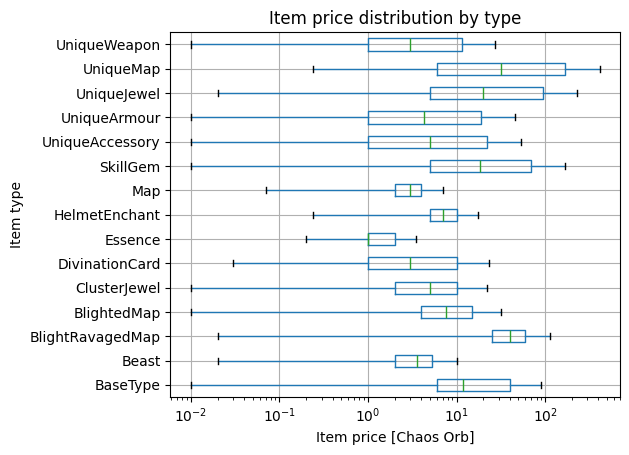

In [11]:
top_types = items_processed["Type"].value_counts().head(15).index
price_distr_by_type = items_processed[items_processed["Type"].isin(top_types)]

plt.figure(figsize=(12,8))

price_distr_by_type.boxplot(column="Value", by="Type", vert=False, showfliers=False)

plt.xscale("log")
plt.xlabel("Item price [Chaos Orb]")
plt.ylabel("Item type")
plt.title("Item price distribution by type")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Conclusion:** The boxplot reveals substantial variability in item prices across most item categories.In many cases, item prices vary by several orders of magnitude indicating that items within the same category can differ greatly in value (although outliers are already hidden in the plot). This suggests that the market price of an item is strongly influenced by its specific properties and rarity rather than by its general type alone. At the same time, some categories have narrower price ranges, suggesting more stable prices. In contrast, other categories display very wide distributions, where a small number of extremely valuable items coexist with a large number of low-value items.

### Price dominance within item types

In [12]:
# Most valuable item in each type
top_item_per_type = (items_processed.loc[items_processed.groupby("Type")["Value"].idxmax()][["Type", "Name", "Value", "Confidence"]].sort_values("Value", ascending=False).reset_index(drop=True))
top_item_per_type

,Type,Name,Value,Confidence
0,BaseType,Stygian Vise,3859155.000,Low
1,UniqueArmour,The Apostate,2723020.000,Low
2,UniqueAccessory,Demigod's Eye,2424828.000,Low
3,UniqueWeapon,Demigod's Authority,2332007.680,Low
4,SkillGem,Volcanic Fissure of Snaking,2195928.600,Low
5,BlightRavagedMap,Blight-ravaged Courthouse Map,1820517.930,Low
6,Beast,Crypt Weaver,1621692.600,Low
7,UniqueMap,Cursed Refuse,1549845.000,Low
8,UniqueJewel,Emperor's Mastery,913847.220,Low
9,ForbiddenJewel,Indomitable Resolve,446858.000,Low


The extremely high price values observed above are associated exclusively with low confidence estimates. These values typically correspond to very rare items, special game artefacts or exceptionally rare and high prizes obtained by top players. As a result, they represent statistical outliers rather than typical market behaviour and therefore do not accurately reflect the representative value of the most expensive items within each type. To ensure more reliable results, the analysis was restricted to observations with medium and high confidence levels only.

In [13]:
# Most valuable item in each type with Medium or High confidence
high_conf_items_processed = items_processed[items_processed["Confidence"].isin(["Medium", "High"])]
high_conf_items_processed.reset_index(drop=True).to_csv("../data/items_data_processed/high_conf_items_processed_day.csv",sep=";",index=False)

highconf_top_item_per_type = (high_conf_items_processed.loc[high_conf_items_processed.groupby("Type")["Value"].idxmax()][["Type", "Name", "Value", "Confidence"]].sort_values("Value", ascending=False).reset_index(drop=True))
highconf_top_item_per_type

,Type,Name,Value,Confidence
0,UniqueAccessory,Replica Bated Breath,1636590.860,Medium
1,UniqueJewel,Voices,870858.000,High
2,SkillGem,Awakened Enlighten Support,734526.820,Medium
3,ForbiddenJewel,Undeniable,314961.600,High
4,UniqueRelic,The Original Scripture,234107.230,High
5,BaseType,Simplex Amulet,170237.720,Medium
6,UniqueFlask,Progenesis,107685.915,Medium
7,Runegraft,Runegraft of the Angler,102706.690,High
8,UniqueArmour,Asphyxia's Wrath,97133.820,Medium
9,UniqueWeapon,Foulborn Hand of Thought and Motion,88400.000,High


In [14]:
#Price dominance of top Items within Types
median_price = high_conf_items_processed.groupby("Type")["Value"].median() 
highconf_top_item_per_type["median_type_value"] = highconf_top_item_per_type["Type"].map(median_price) 
highconf_top_item_per_type["value_vs_median"] = (highconf_top_item_per_type["Value"] / highconf_top_item_per_type["median_type_value"]).round(2) 
highconf_top_item_per_type

,Type,Name,Value,Confidence,median_type_value,value_vs_median
0,UniqueAccessory,Replica Bated Breath,1636590.860,Medium,5.00,327318.17
1,UniqueJewel,Voices,870858.000,High,20.00,43542.90
2,SkillGem,Awakened Enlighten Support,734526.820,Medium,12.00,61210.57
3,ForbiddenJewel,Undeniable,314961.600,High,100.00,3149.62
4,UniqueRelic,The Original Scripture,234107.230,High,10.00,23410.72
5,BaseType,Simplex Amulet,170237.720,Medium,9.30,18305.13
6,UniqueFlask,Progenesis,107685.915,Medium,5.00,21537.18
7,Runegraft,Runegraft of the Angler,102706.690,High,10.00,10270.67
8,UniqueArmour,Asphyxia's Wrath,97133.820,Medium,4.00,24283.46
9,UniqueWeapon,Foulborn Hand of Thought and Motion,88400.000,High,2.00,44200.00


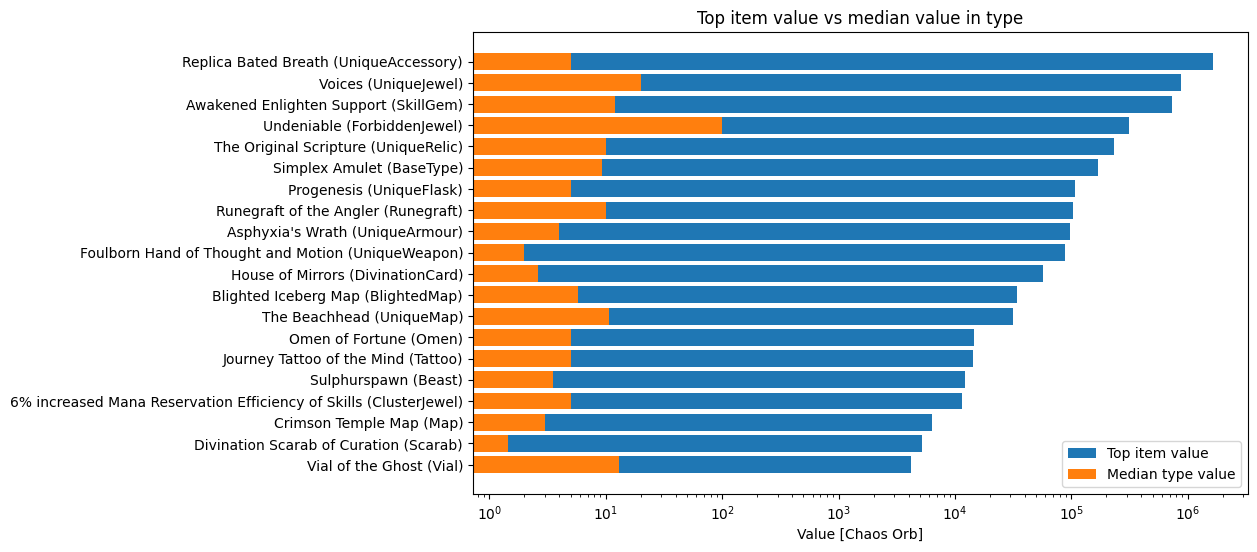

In [15]:
top20 = highconf_top_item_per_type.head(20)


plt.figure(figsize=(10,6))

y = range(len(top20))

plt.barh(y, top20["Value"], label="Top item value")
plt.barh(y, top20["median_type_value"], label="Median type value")
plt.yticks(y, top20["Name"].astype(str) + " (" + top20["Type"].astype(str) + ")")
plt.xlabel("Value [Chaos Orb]")
plt.xscale("log")
plt.title("Top item value vs median value in type")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

### Market Value Concentration

In [16]:
# Average value of each item across all observations
item_values = (high_conf_items_processed.groupby("Name")["Value"].mean().sort_values(ascending=False))

# Total market value (sum of average item values)
total_market_value = item_values.sum()

# Value of the 20 most expensive items
top20_items = item_values.head(20)
top20_value = top20_items.sum()

# Percentage of total market value represented by top 20 items
percentage_top20 = (top20_value / total_market_value) * 100
print(f"Top 20 items generate {percentage_top20:.2f}% of total market value")



Top 20 items generate 44.50% of total market value


**Conclusion:** The boxplot analysis revealed that price distributions within many item categories are highly skewed, with most items having relatively low prices while a small number of items reach extremely high values. This pattern reflects a characteristic feature of the Path of Exile economy, where the market structure is highly uneven and dominated by a long tail of rare, high-value items.

This observation is further supported by comparing the most expensive item in each type with the median value of that type. In many cases, the top item is several orders of magnitude more valuable than the typical item within the same type, confirming that the economic value of item types is largely driven by a small number of extremely rare items.

The analysis of market value concentration provides additional evidence for this pattern. The twenty most expensive items account for approximately 44.5% of the total market value, indicating that a relatively small number of items dominate a substantial portion of the overall economy.

Because prices vary a lot across categories, analysing all items together may hide important patterns. Therefore, the future planned analysis will focus on a selected subset of representative items, which allows for a clearer investigation of price dynamics and market behaviour across different leagues.


## Price distribution by League

<Figure size 1000x600 with 0 Axes>

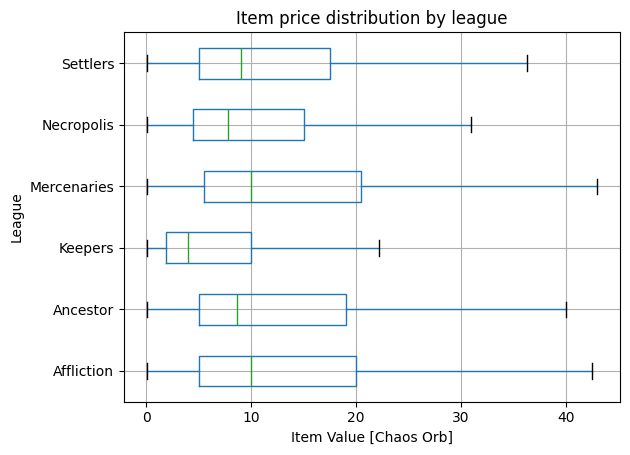

In [17]:
plt.figure(figsize=(10,6))

high_conf_items_processed.boxplot(column="Value",by="League",vert=False,showfliers=False)

plt.xlabel("Item Value [Chaos Orb]")
plt.ylabel("League")
plt.title("Item price distribution by league")

plt.suptitle("")
plt.tight_layout()
plt.show()

Item prices exhibit a similar statistical structure across all analysed leagues. The medians remain at comparable levels, while differences in dispersion between leagues are moderate. The distributions are consistently right-skewed, indicating that most items have relatively low values, whereas a small number of items reach substantially higher prices. This suggests that despite differences between leagues, the structure of the item economy remains broadly stable.

## Price evolution in each league

The first methodological issue concerned whether the duration of each league should be normalised, as one of them — **Settlers** — lasted significantly longer than the others.

It was decided that the league duration won't be normalised in order to preserve the real dynamics of item prices. This allows the analysis to capture how market behaviour evolves during the actual progression of each league, including early-league price spikes and subsequent market stabilisation.

An additional motivation for keeping the original timeline is the unusual duration of the Settlers league. Unlike standard Path of Exile leagues, which typically last around four months, the duration of this league was extended multiple times. At the start of the league, players were not aware that it would last significantly longer, which meant that economic decisions, progression strategies, and the pace of achieving in-game goals were made under the assumption of a typical league cycle. The extension occurred because the developers were focused on the development of Path of Exile 2 and postponed the release of the next league.

Preserving the real timeline therefore allows observation of how the market evolved during this unexpectedly prolonged league. In particular, it provides an opportunity to analyse the gradual freezing of the market as players activity declines over time.

In [18]:
# Average price per day for each league
avg_price_per_day = (high_conf_items_processed.groupby(["League", "Day"])["Value"].mean().reset_index())

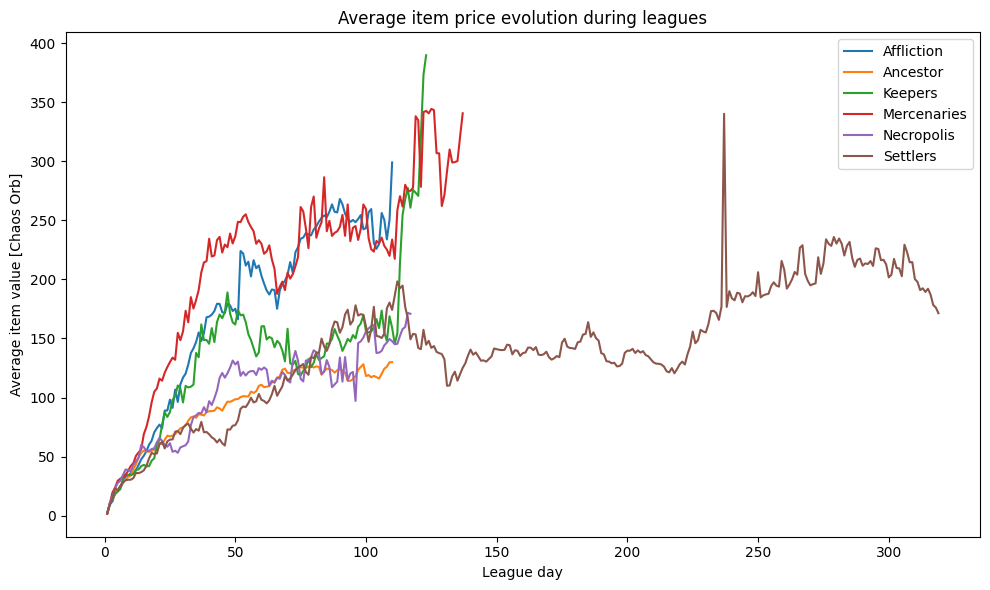

In [19]:
#Average item value evolution during leagues
plt.figure(figsize=(10,6))

for league in avg_price_per_day["League"].unique():
    league_data = avg_price_per_day[avg_price_per_day["League"] == league]
    plt.plot(league_data["Day"],league_data["Value"],label=league)

plt.xlabel("League day")
plt.ylabel("Average item value [Chaos Orb]")
plt.title("Average item price evolution during leagues")
plt.legend()
plt.tight_layout()

plt.show()

In order to better compare price evolution during leagus  the data was also filtered by 110 days - lenght of the two shortest leagues being analysed. 

In [20]:
# filtering 110 first days

first_110_days = avg_price_per_day[avg_price_per_day["Day"] <= 110]


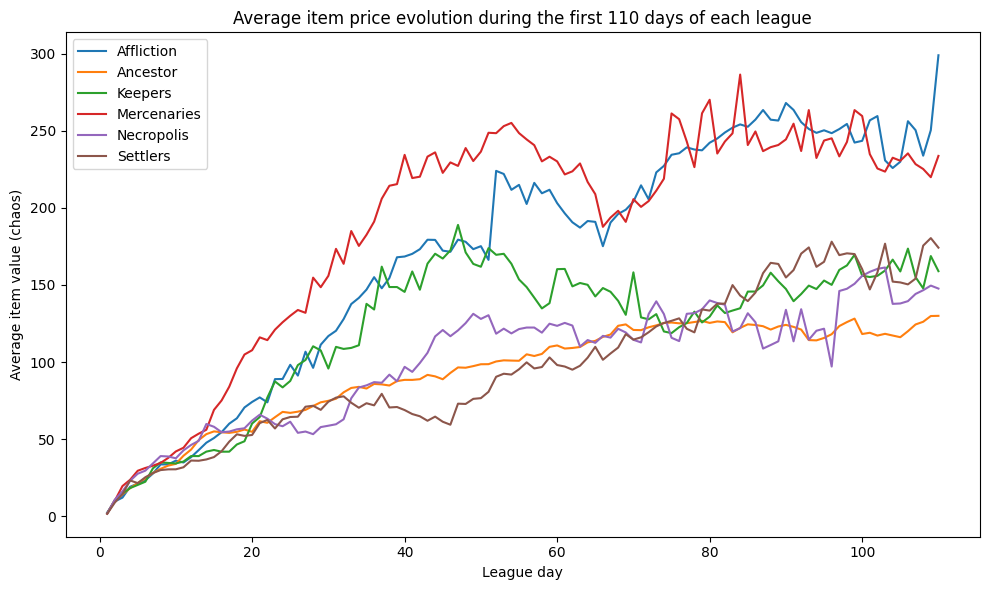

In [21]:
#Average item value evolution during 110 days of each league
plt.figure(figsize=(10,6))

for league in first_110_days["League"].unique():
    league_data = first_110_days[
        first_110_days["League"] == league]
    plt.plot(league_data["Day"],league_data["Value"],label=league)

plt.xlabel("League day")
plt.ylabel("Average item value (chaos)")
plt.title("Average item price evolution during the first 110 days of each league")

plt.legend()
plt.tight_layout()

plt.show()

**Conclusions:**

**1. Common upward trend at the beginning of a league**

Across all leagues, the first days are characterised by a rapid increase in the average price of items. This reflects a typical mechanism of the Path of Exile economy: at the beginning of a league, the supply of valuable items is very limited while demand from players is high. As the league progresses, more items enter the market, gradually leading to price stabilisation.

At the same time, even if a valuable item drops very early in the league, it usually cannot be sold for an extremely high price. This is because players have not yet accumulated enough currency to afford such prices. As more currency enters the economy over time, the market becomes capable of supporting higher prices.

**2. Differences in price levels between leagues**

Despite the similar overall trend, the level of prices differs noticeably between leagues. The highest average prices during the analysed period are observed in the **Mercenaries** and **Affliction** leagues, where the average item value exceeds 250 chaos in the later stages of the analysed period. In contrast, leagues such as **Ancestor** are characterised by substantially lower average values.

**3. Market stabilisation phase**

After the initial period of rapid growth, prices in most leagues begin to stabilise and price variability decreases. This suggests that the market gradually approaches a relative equilibrium between supply and demand.

**4. Price variability during the league**

In the second half of the analysed period, greater short-term price fluctuations become visible. These changes may be caused by new farming strategies, changes in player behaviour, or shifts in the supply of certain items.

**5. Overall market dynamics**

Although price levels differ between leagues, the general market dynamics appear similar across them. An initial phase of rapid price growth is followed by a more stable period in which the market gradually reaches equilibrium.
